# Tolke data: Badetemperatur på Nordnes Sjøbad

Nordnes Sjøbad i Bergen har ein sensor som måler **sjøtemperaturen** og **lufttemperaturen** kvar time. Målingane har gått sidan mai 2024, og alle ligg i ei CSV-fil:

<https://github.com/hausnes/nordnes-sjobad/blob/data/temperatur.csv>

Ein kopi (henta 4. november 2026) ligg i `data/nordnes-sjobad.csv`. Vil du ha dei aller nyaste dataa, kan du lese direkte frå nettet i staden:

```python
url = "https://raw.githubusercontent.com/hausnes/nordnes-sjobad/data/temperatur.csv"
data = pd.read_csv(url, ...)
```

Notatboka går frå det enkle til det meir avanserte:

| Nivå | Innhald |
|---|---|
| 1 | Bli kjent med dataa: lese fila, sjå på tabellen, enkle tal |
| 2 | Rydde: manglande verdiar, duplikat, umoglege målingar og hol |
| 3 | Visualisere: grafar over heile perioden, éi veke og histogram |
| 4 | Samanfatte: døgn- og månadssnitt, samanlikne år, døgnvariasjon |
| 5 | Djupare: glidande gjennomsnitt, samanheng mellom luft og sjø, kor mykje kan vi stole på dataa? |

Køyr cellene i rekkjefølgje med `Shift + Enter`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 4)   # standard storleik på figurane

---
## Nivå 1: Bli kjent med dataa

Vi prøver først å lese fila på den enklaste måten:

In [2]:
data = pd.read_csv("data/nordnes-sjobad.csv")
data.head()

,tid,temperatur,lufttemperatur
0,2024-05-21 13:29:27,15.6,NaN
1,2024-05-21 21:49:32,17.6,NaN
2,2024-05-21 21:59:44,17.3,NaN
3,2024-05-21 22:30:47,17.3,NaN
4,2024-05-21 22:41:43,17.5,NaN


Det ser fint ut. Men sjå kva **datatype** kolonnane har:

In [3]:
data.dtypes

tid               str
temperatur        str
lufttemperatur    str
dtype: object

Temperaturane er lesne som **tekst** (`object` eller `str`), ikkje som tal! Då kan vi ikkje rekne gjennomsnitt eller teikne grafar. Det betyr at det finst noko i kolonnen som ikkje er eit tal. La oss leite:

In [4]:
data[data["temperatur"] == "-"].head()

,tid,temperatur,lufttemperatur
176,2024-05-28 21:00:03,-,-
177,2024-05-28 22:00:02,-,-
178,2024-05-28 23:00:03,-,-
179,2024-05-29 00:00:03,-,-
180,2024-05-29 01:00:03,-,-


Når sensoren ikkje har fått målt, er det skrive ein bindestrek `-`. Vi seier til Pandas at `-` betyr **manglande verdi** med `na_values="-"`. Samtidig ber vi Pandas tolke `tid` som tidspunkt, og bruke han som indeks:

In [5]:
data = pd.read_csv(
    "data/nordnes-sjobad.csv",
    na_values="-",          # "-" betyr at målinga manglar
    parse_dates=["tid"],    # tid er dato og klokkeslett
    index_col="tid",        # bruk tida som radnamn
)
data.dtypes

temperatur        float64
lufttemperatur    float64
dtype: object

No er begge kolonnane `float64`, altså desimaltal. Manglande målingar heiter `NaN` (*Not a Number*).

### Første og siste rader

In [6]:
data.head()

,temperatur,lufttemperatur
tid,,
2024-05-21 13:29:27,15.6,NaN
2024-05-21 21:49:32,17.6,NaN
2024-05-21 21:59:44,17.3,NaN
2024-05-21 22:30:47,17.3,NaN
2024-05-21 22:41:43,17.5,NaN


In [7]:
data.tail()

,temperatur,lufttemperatur
tid,,
2026-11-04 17:00:02,8.9,8.3
2026-11-04 18:00:02,8.8,6.9
2026-11-04 19:00:05,8.6,6.9
2026-11-04 20:00:03,8.7,6.7
2026-11-04 21:00:01,8.8,6.6


### Kor mykje data har vi?

In [8]:
print("Tal på rader:", len(data))
print("Første måling:", data.index.min())
print("Siste måling:", data.index.max())
print("Periode:", data.index.max() - data.index.min())

Tal på rader: 21167
Første måling: 2024-05-21 13:29:27
Siste måling: 2026-11-04 21:00:01
Periode: 897 days 07:30:34


### Enkel statistikk

`describe()` gir ei rask oversikt over kvar kolonne:

| Rad | Tyding |
|---|---|
| `count` | tal på målingar (utan manglande verdiar) |
| `mean` | gjennomsnitt |
| `std` | standardavvik: kor mykje verdiane spreier seg |
| `min`, `max` | lågaste og høgaste verdi |
| `25%`, `50%`, `75%` | kvartilar. `50%` er medianen: halvparten av målingane er lågare enn denne. |

In [9]:
data.describe().round(1)

,temperatur,lufttemperatur
count,20504.0,20697.0
mean,11.3,10.2
std,4.1,5.6
min,-50.0,-8.1
25%,8.0,6.4
50%,11.8,10.6
75%,14.3,13.7
max,24.2,30.8


Legg merke til **minimum for sjøtemperaturen: −50 °C**. Det er umogleg! Sjøvatn frys ved ca. −1,9 °C. Dette tek vi tak i på nivå 2.

### Når var det varmast?

`max()` gir den høgaste verdien. `idxmax()` gir *indeksen* (her: tidspunktet) til den høgaste verdien.

In [10]:
print("Varmaste sjø:", data["temperatur"].max(), "°C, den", data["temperatur"].idxmax())
print("Varmaste luft:", data["lufttemperatur"].max(), "°C, den", data["lufttemperatur"].idxmax())
print("Kaldaste luft:", data["lufttemperatur"].min(), "°C, den", data["lufttemperatur"].idxmin())

Varmaste sjø: 24.2 °C, den 2025-07-20 18:00:02
Varmaste luft: 30.8 °C, den 2024-05-23 14:00:04
Kaldaste luft: -8.1 °C, den 2026-01-08 09:00:06


### Plukke ut ein periode

Fordi tida er indeks, kan vi plukke ut periodar med `data.loc[...]`:

In [11]:
data.loc["2026-07-01 12:00":"2026-07-01 18:00"]

,temperatur,lufttemperatur
tid,,
2026-07-01 12:00:02,15.4,16.4
2026-07-01 13:00:02,15.9,17.8
2026-07-01 14:00:04,15.5,16.7
2026-07-01 15:00:06,16.9,17.4
2026-07-01 16:00:03,16.5,17.8
2026-07-01 17:00:07,16.9,17.0
2026-07-01 18:00:02,17.5,17.1


---
## Nivå 2: Rydde i dataa

Ekte måledata er nesten aldri perfekte. Før vi tolkar noko, må vi sjekke **datakvaliteten**. Vi ser etter fire ting:

1. manglande verdiar
2. duplikat (same tidspunkt fleire gonger)
3. umoglege eller usannsynlege verdiar
4. hol i tidsserien

### 1. Manglande verdiar

In [12]:
data.isna().sum()

temperatur        663
lufttemperatur    470
dtype: int64

Lufttemperaturen manglar på fleire rader enn sjøtemperaturen, fordi luftsensoren kom på plass eit døgn seinare enn sjøsensoren:

In [13]:
print("Første måling av lufttemperatur:", data["lufttemperatur"].first_valid_index())

Første måling av lufttemperatur: 2024-05-22 10:25:05


### 2. Duplikat

In [14]:
duplikat = data.index.duplicated(keep=False)
data[duplikat]

,temperatur,lufttemperatur
tid,,
2024-05-22 01:00:04,16.9,NaN
2024-05-22 01:00:04,16.8,NaN
2024-12-16 15:08:10,8.4,4.9
2024-12-16 15:08:10,8.4,4.9
2024-12-16 15:08:10,8.4,4.9
2025-10-26 02:00:04,11.6,9.5
2025-10-26 02:00:04,11.5,9.7
2026-04-23 13:16:41,9.8,9.1
2026-04-23 13:16:41,9.8,9.1


Nokre tidspunkt er lagra to eller tre gonger. Den eine (26. oktober 2025 kl. 02:00) kjem av overgangen frå sommartid til vintertid. Vi beheld den første av kvar:

In [15]:
data = data[~data.index.duplicated(keep="first")]
print("Rader etter at duplikat er fjerna:", len(data))

Rader etter at duplikat er fjerna: 21162


`~` betyr «ikkje». Vi beheld altså alle rader som **ikkje** er duplikat.

### 3. Umoglege verdiar

Ein graf avslører ofte feil raskare enn tabellar:

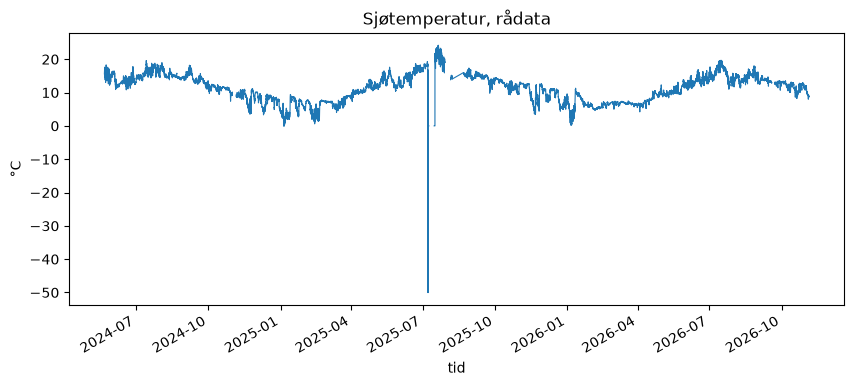

In [16]:
data["temperatur"].plot(title="Sjøtemperatur, rådata", ylabel="°C", linewidth=0.8);

Den loddrette streken ned til −50 °C sommaren 2025 er openbert ein feil. Vi ser nærare på juli 2025:

In [17]:
juli = data.loc["2025-07"]
juli[juli["temperatur"] < 5]

,temperatur,lufttemperatur
tid,,
2025-07-07 13:00:03,-50.0,15.9
2025-07-07 18:00:03,-50.0,15.5
2025-07-07 19:00:03,-50.0,16.1
2025-07-07 20:00:03,-50.0,17.3
2025-07-08 16:00:03,0.0,19.3
2025-07-08 17:00:04,0.0,17.8
2025-07-08 18:00:03,0.0,18.3
2025-07-15 13:00:03,0.0,26.3
2025-07-15 14:00:04,0.0,25.0


Her er det fleire målingar på **nøyaktig 0,0 °C** midt i ei hetebølgje, medan lufta held 20–26 °C. Det er nesten sikkert sensorfeil. Mange sensorar sender ein fast «feilverdi» når noko går gale. DS18B20, som du brukar sjølv, sender til dømes **−127** når han ikkje får kontakt, og **85** rett etter oppstart.

Vi lagar to enkle reglar:

- Under **−2 °C** er umogleg for sjøvatn.
- Under **5 °C** i perioden **juni–september** er urealistisk i Bergen.

Feilverdiane gjer vi om til `NaN` i staden for å slette radene. Då ser vi framleis at det var eit forsøk på å måle.

In [18]:
umogleg = data["temperatur"] < -2
sommar = data.index.month.isin([6, 7, 8, 9])
urealistisk = sommar & (data["temperatur"] < 5)

feil = umogleg | urealistisk          # | betyr "eller"
print("Tal på feilmålingar:", feil.sum())

snitt_for = data.loc["2025-07", "temperatur"].mean()
data.loc[feil, "temperatur"] = np.nan
snitt_etter = data.loc["2025-07", "temperatur"].mean()

print(f"Snitt i juli 2025 før rydding:  {snitt_for:.1f} °C")
print(f"Snitt i juli 2025 etter rydding: {snitt_etter:.1f} °C")

Tal på feilmålingar: 32
Snitt i juli 2025 før rydding:  18.3 °C
Snitt i juli 2025 etter rydding: 20.0 °C


Berre 32 feilmålingar av over 21 000 endra gjennomsnittet for juli 2025 med nesten **2 grader**. Det viser kor viktig det er å rydde før ein tolkar!

> **Tenk over:** Vi bestemte sjølv grensene (−2 °C og 5 °C). Er dei rimelege? Kva om ein ekte, uvanleg kald dag blir fjerna? Slike val bør alltid skrivast ned når du presenterer resultata dine.

### 4. Hol i tidsserien

Normalt kjem det ei måling kvar time. Vi reknar ut tida mellom kvar måling og ser etter dei største hola:

In [19]:
mellomrom = data.index.to_series().diff()
mellomrom.sort_values(ascending=False).head(5)

tid
2025-08-21 21:40:49   14 days 01:40:46
2025-08-31 11:00:04    0 days 11:00:00
2024-05-21 21:49:32    0 days 08:20:05
2024-06-01 08:00:02    0 days 07:00:00
2026-09-02 16:00:02    0 days 06:00:00
Name: tid, dtype: timedelta64[us]

Det største holet er på **over 14 dagar** i august 2025. Det tyder at målingane i august 2025 berre dekkjer delar av månaden. Eit månadssnitt for august 2025 er derfor mindre til å stole på enn for dei andre månadane.

Elles er det ein del timar der det står `-` i fila (dei vart `NaN` då vi las fila).

---
## Nivå 3: Visualisere

### Heile perioden

Vi teiknar sjø og luft i same figur. Begge er i °C, så dei kan dele y-akse.

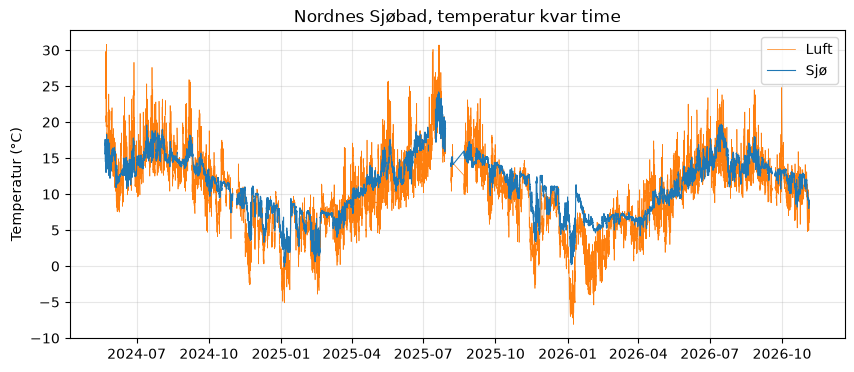

In [20]:
fig, ax = plt.subplots()
ax.plot(data.index, data["lufttemperatur"], label="Luft", linewidth=0.5, color="tab:orange")
ax.plot(data.index, data["temperatur"], label="Sjø", linewidth=0.8, color="tab:blue")
ax.set_title("Nordnes Sjøbad, temperatur kvar time")
ax.set_ylabel("Temperatur (°C)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

Kva ser du?

- Både luft og sjø har ein tydeleg **årssyklus**: varmt om sommaren, kaldt om vinteren.
- Lufttemperaturen **varierer mykje meir** enn sjøtemperaturen, både frå time til time og gjennom året.
- Om vinteren er sjøen **varmare** enn lufta.
- Den rette streken i august 2025 er eit **hol** i dataa. Matplotlib trekkjer ein strek mellom dei to punkta på kvar side av holet.

### Éi veke

Vi zoomar inn på hetebølgja i juli 2025:

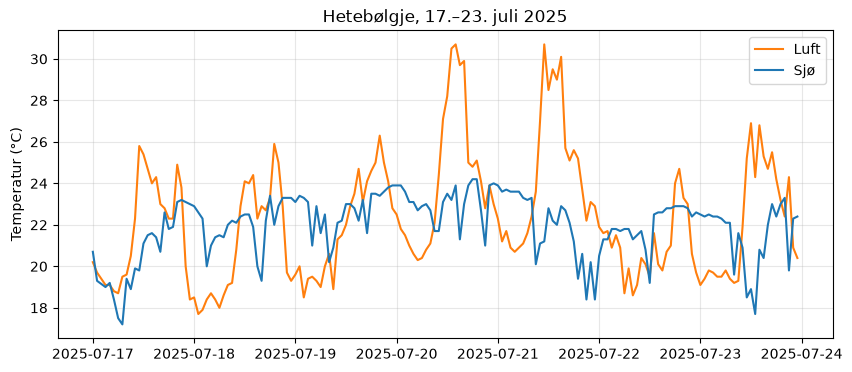

In [21]:
veke = data.loc["2025-07-17":"2025-07-23"]

fig, ax = plt.subplots()
ax.plot(veke.index, veke["lufttemperatur"], label="Luft", color="tab:orange")
ax.plot(veke.index, veke["temperatur"], label="Sjø", color="tab:blue")
ax.set_title("Hetebølgje, 17.–23. juli 2025")
ax.set_ylabel("Temperatur (°C)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

No ser vi **døgnvariasjonen**: Lufta blir varm på dagen og kjølegare om natta. Sjøen varierer mykje mindre, men følgjer etter.

### Histogram: Kor ofte er det kor varmt?

Eit histogram deler temperaturane inn i «bøtter» og tel kor mange målingar som hamnar i kvar bøtte.

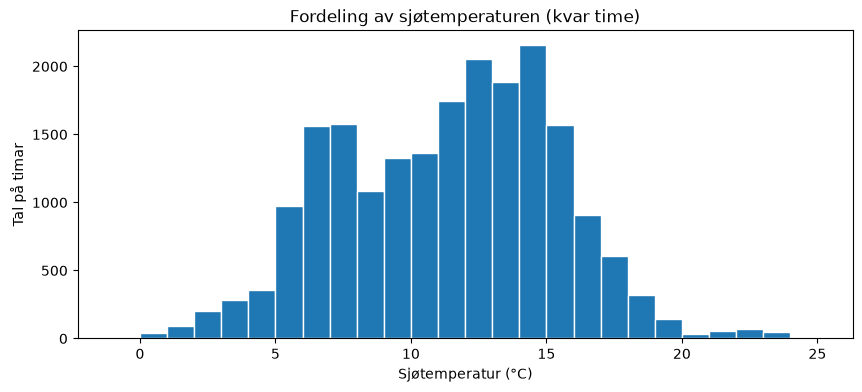

In [22]:
ax = data["temperatur"].plot.hist(bins=range(-1, 26), edgecolor="white")
ax.set_title("Fordeling av sjøtemperaturen (kvar time)")
ax.set_xlabel("Sjøtemperatur (°C)")
ax.set_ylabel("Tal på timar")
plt.show()

---
## Nivå 4: Samanfatte

Over 21 000 målingar er mange å halde styr på. Vi kan **samanfatte** dei, til dømes til eitt tal per dag eller per månad.

### Døgnsnitt med `resample`

`resample("D")` deler dataa inn i døgn (D = *day*). Deretter reknar vi gjennomsnittet for kvart døgn.

In [23]:
dogn = data.resample("D").mean()
dogn.head()

,temperatur,lufttemperatur
tid,,
2024-05-21,17.185714,NaN
2024-05-22,16.114815,26.014286
2024-05-23,16.150000,23.616667
2024-05-24,15.616667,17.020833
2024-05-25,16.012500,17.537500


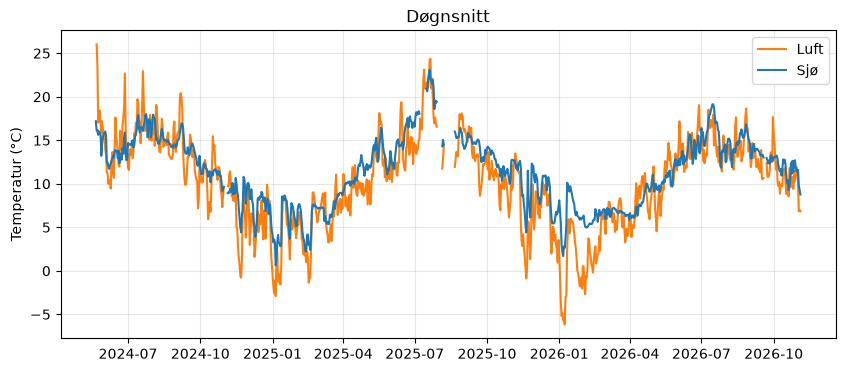

In [24]:
fig, ax = plt.subplots()
ax.plot(dogn.index, dogn["lufttemperatur"], label="Luft", color="tab:orange")
ax.plot(dogn.index, dogn["temperatur"], label="Sjø", color="tab:blue")
ax.set_title("Døgnsnitt")
ax.set_ylabel("Temperatur (°C)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

Grafen blir mykje roligare. Legg merke til hola, der det ikkje finst data.

Andre bokstavar du kan bruke i `resample`: `"h"` (time), `"W"` (veke), `"MS"` (månad), `"YS"` (år).

### Månadsstatistikk

Vi kan rekne fleire ting samtidig med `agg`. Vi tek med `count` for å sjå kor mange målingar kvart snitt byggjer på.

In [25]:
manad = data["temperatur"].resample("MS").agg(["mean", "min", "max", "count"])
manad.round(1)

,mean,min,max,count
tid,,,,
2024-05-01,15.6,12.2,18.3,235
2024-06-01,13.4,10.8,17.8,703
2024-07-01,16.0,13.5,19.6,744
2024-08-01,15.3,13.6,19.0,721
2024-09-01,14.3,11.0,18.2,720
2024-10-01,11.2,7.4,13.3,731
2024-11-01,8.6,3.5,11.1,614
2024-12-01,7.5,3.3,10.1,741
2025-01-01,5.4,-0.1,9.4,744


Sjå på `count` for august 2025. Ein månad med 31 dagar skal ha ca. 744 timar. August 2025 har berre rundt 290.

### Samanlikne år

Var sommaren 2025 varmare enn 2024 og 2026? Vi grupperer på **år** og **månad** med `groupby`, og legg åra som kolonnar med `unstack`:

In [26]:
ar_manad = data.groupby([data.index.month, data.index.year])["temperatur"].mean().unstack()
ar_manad.index.name = "månad"
ar_manad.columns.name = "år"
ar_manad.round(1)

år,2024,2025,2026
månad,,,
1,NaN,5.4,6.5
2,NaN,5.5,6.0
3,NaN,7.2,6.7
4,NaN,10.8,8.0
5,15.6,13.3,10.5
6,13.4,15.1,13.6
7,16.0,20.0,16.0
8,15.3,15.4,14.8
9,14.3,14.4,13.4


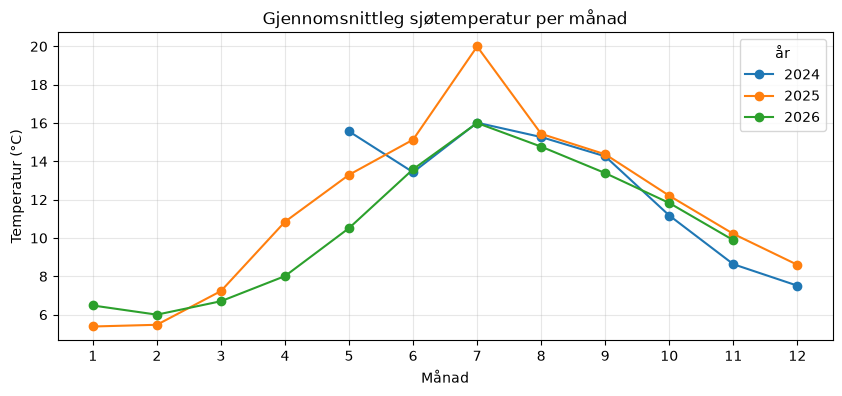

In [27]:
ax = ar_manad.plot(marker="o")
ax.set_title("Gjennomsnittleg sjøtemperatur per månad")
ax.set_xlabel("Månad")
ax.set_ylabel("Temperatur (°C)")
ax.set_xticks(range(1, 13))
ax.grid(alpha=0.3)
plt.show()

Juli 2025 skil seg tydeleg ut som den varmaste månaden i heile datasettet. (Mai 2024 byggjer berre på dei siste ti dagane i månaden, sidan målingane starta 21. mai.)

### Badedagar

Kor mange dagar per år var sjøen minst 18 °C ein gong i løpet av døgnet?

In [28]:
dogn_maks = data["temperatur"].resample("D").max()
badedag = dogn_maks >= 18
badedag.groupby(badedag.index.year).sum()

tid
2024    16
2025    27
2026    10
Name: temperatur, dtype: int64

Hugs at 2024 startar i mai og 2026 sluttar i november. Talet for kvart år dekkjer derfor ikkje heilt like periodar, men sommaren er med alle åra.

### Døgnvariasjon

Er det varmare klokka 15 enn klokka 06? Vi grupperer på **time på døgnet** og reknar gjennomsnittet for alle dagar:

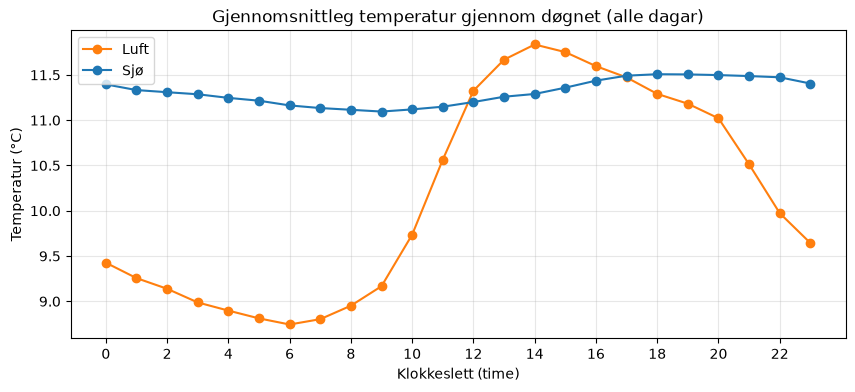

Døgnvariasjon luft: 3.1 °C
Døgnvariasjon sjø:  0.4 °C


In [29]:
time_snitt = data.groupby(data.index.hour).mean()

fig, ax = plt.subplots()
ax.plot(time_snitt.index, time_snitt["lufttemperatur"], marker="o", label="Luft", color="tab:orange")
ax.plot(time_snitt.index, time_snitt["temperatur"], marker="o", label="Sjø", color="tab:blue")
ax.set_title("Gjennomsnittleg temperatur gjennom døgnet (alle dagar)")
ax.set_xlabel("Klokkeslett (time)")
ax.set_ylabel("Temperatur (°C)")
ax.set_xticks(range(0, 24, 2))
ax.legend()
ax.grid(alpha=0.3)
plt.show()

print("Døgnvariasjon luft:", round(time_snitt["lufttemperatur"].max() - time_snitt["lufttemperatur"].min(), 1), "°C")
print("Døgnvariasjon sjø: ", round(time_snitt["temperatur"].max() - time_snitt["temperatur"].min(), 1), "°C")

Lufta er kaldast rundt klokka 6–7 og varmast rundt klokka 14. Sjøen endrar seg knapt gjennom døgnet.

---
## Nivå 5: Djupare analyse

### Glidande gjennomsnitt

Eit **glidande gjennomsnitt** (*rolling mean*) reknar snittet av dei siste målingane for kvart punkt. Det glattar ut grafen utan å samle dataa i faste bolkar, slik `resample` gjer.

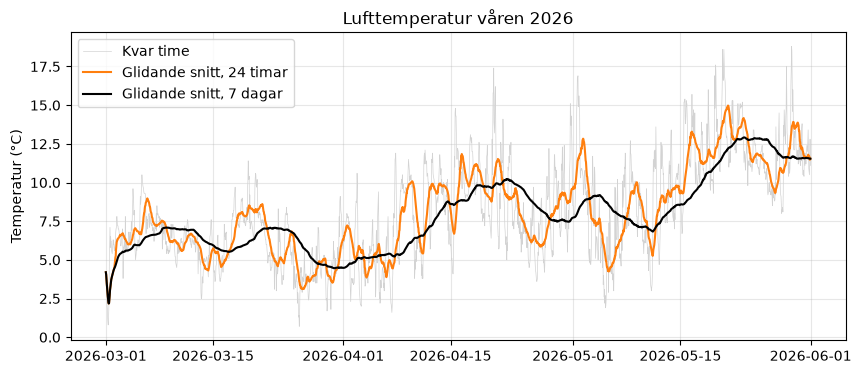

In [30]:
var = data.loc["2026-03-01":"2026-05-31", "lufttemperatur"]

fig, ax = plt.subplots()
ax.plot(var.index, var, label="Kvar time", linewidth=0.5, color="lightgray")
ax.plot(var.index, var.rolling("24h").mean(), label="Glidande snitt, 24 timar", color="tab:orange")
ax.plot(var.index, var.rolling("7D").mean(), label="Glidande snitt, 7 dagar", color="black")
ax.set_title("Lufttemperatur våren 2026")
ax.set_ylabel("Temperatur (°C)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

### Samanheng mellom luft og sjø

Eit **spreiingsplott** (*scatter plot*) viser kvar dag som eitt punkt: lufttemperatur på x-aksen og sjøtemperatur på y-aksen.

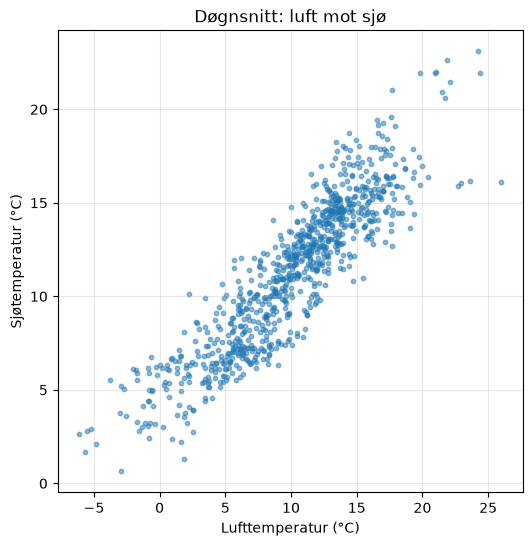

Korrelasjonskoeffisient: r = 0.90


In [31]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(dogn["lufttemperatur"], dogn["temperatur"], s=10, alpha=0.5)
ax.set_title("Døgnsnitt: luft mot sjø")
ax.set_xlabel("Lufttemperatur (°C)")
ax.set_ylabel("Sjøtemperatur (°C)")
ax.grid(alpha=0.3)
plt.show()

r = dogn["lufttemperatur"].corr(dogn["temperatur"])
print(f"Korrelasjonskoeffisient: r = {r:.2f}")

**Korrelasjonskoeffisienten** `r` ligg mellom −1 og 1:

- nær **1**: når det eine aukar, aukar det andre òg
- nær **0**: ingen (lineær) samanheng
- nær **−1**: når det eine aukar, minkar det andre

Her er `r` rundt 0,9, som er ein sterk samanheng. Men **korrelasjon er ikkje årsak**: Lufta varmar ikkje opp sjøen åleine. Begge blir påverka av sola og årstida.

### Kvifor er sjøen varmare enn lufta om vinteren?

Vi reknar ut kor mykje varmare sjøen er enn lufta i gjennomsnitt, månad for månad:

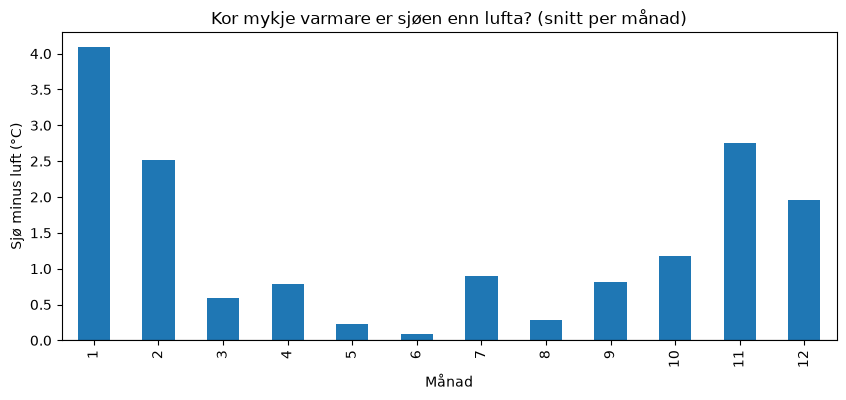

In [32]:
skilnad = data["temperatur"] - data["lufttemperatur"]
skilnad_manad = skilnad.groupby(skilnad.index.month).mean()

ax = skilnad_manad.plot.bar(color="tab:blue")
ax.set_title("Kor mykje varmare er sjøen enn lufta? (snitt per månad)")
ax.set_xlabel("Månad")
ax.set_ylabel("Sjø minus luft (°C)")
ax.axhline(0, color="black", linewidth=0.8)
plt.show()

Sjøen er varmare enn lufta alle månadane i snitt, men særleg om vinteren. Vatn har høg **spesifikk varmekapasitet**: det trengst mykje energi for å varme det opp, og det held på varmen lenge. Sjøen «hugsar» derfor sommaren langt utover hausten, og endrar seg seinare enn lufta.

### Kor mykje kan vi stole på dataa?

Ein god forskar spør alltid: *Kor sikre er desse tala?*

- **Oppløysing:** Dataa er lagra med éin desimal (0,1 °C). Mindre endringar kan vi ikkje sjå.
- **Nøyaktigheit:** Vi veit ikkje kva sensor Nordnes Sjøbad brukar. Er det ein DS18B20, er nøyaktigheita ±0,5 °C. Ein skilnad på 0,3 °C mellom to dagar kan altså vere målefeil.
- **Plassering:** Kvar sit sensorane? Kor djupt er sjøsensoren? Står luftsensoren i skuggen? Lufttemperaturar på over 30 °C i mai 2024 kan tyde på at sola skin rett på sensoren. Samanlikn gjerne med offisielle målingar frå Meteorologisk institutt på <https://seklima.met.no>.
- **Datahol og feilverdiar:** Vi har sett at éin feil kan endre eit månadssnitt mykje. Kor mange målingar eit snitt byggjer på (`count`) er derfor viktig å vise.

Desse spørsmåla gjeld òg for dine eigne målingar i del 3.

---
## Oppsummering

| Teknikk | Kode |
|---|---|
| Lese CSV med tid som indeks | `pd.read_csv(fil, na_values="-", parse_dates=["tid"], index_col="tid")` |
| Oversikt | `head()`, `tail()`, `describe()`, `dtypes` |
| Når skjedde det? | `idxmax()`, `idxmin()` |
| Plukke ut periode | `data.loc["2025-07"]`, `data.loc["2025-07-17":"2025-07-23"]` |
| Manglande verdiar | `isna().sum()` |
| Duplikat | `data[~data.index.duplicated()]` |
| Filtrere | `data[data["temperatur"] < 5]` |
| Hol i tidsserien | `data.index.to_series().diff()` |
| Per dag/månad | `resample("D").mean()`, `resample("MS").agg([...])` |
| Gruppere | `groupby(data.index.hour)`, `groupby(data.index.month)` |
| Glatte ut | `rolling("24h").mean()` |
| Samanheng | `corr()`, `plt.scatter()` |

**Neste:** Prøv deg på [oppgåvene](oppgaver.md)!